In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src" / "data.py").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate src/data.py")
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data import load_data

DATA_DIR = PROJECT_ROOT / "data" / "raw"

In [2]:
cpu_readings, vm_metadata = load_data(DATA_DIR)

aggregate = (
    cpu_readings
    .groupby("timestamp")
    .agg(
        active_vm_count=("vm_id", "nunique"),
        aggregate_cpu_utilization=("avg_cpu", "mean"),
    )
    .reset_index()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

aggregate["elapsed_minutes"] = aggregate["timestamp"] / 60

aggregate.head()

,timestamp,active_vm_count,aggregate_cpu_utilization,elapsed_minutes
0,0,10000,9.396898,0.0
1,300,10000,9.353775,5.0
2,600,10000,9.454383,10.0
3,900,10000,9.224419,15.0
4,1200,10000,9.143503,20.0


In [3]:
aggregate[["active_vm_count", "aggregate_cpu_utilization"]].describe()

,active_vm_count,aggregate_cpu_utilization
count,134.0,134.000000
mean,10000.0,9.388101
std,0.0,0.194987
min,10000.0,8.983613
25%,10000.0,9.250956
50%,10000.0,9.367252
75%,10000.0,9.485657
max,10000.0,9.912175


In [4]:
print("Unique active VM counts:",aggregate["active_vm_count"].nunique(),)
print("Unique CPU utilization values:",aggregate["aggregate_cpu_utilization"].nunique(),)

Unique active VM counts: 1
Unique CPU utilization values: 134


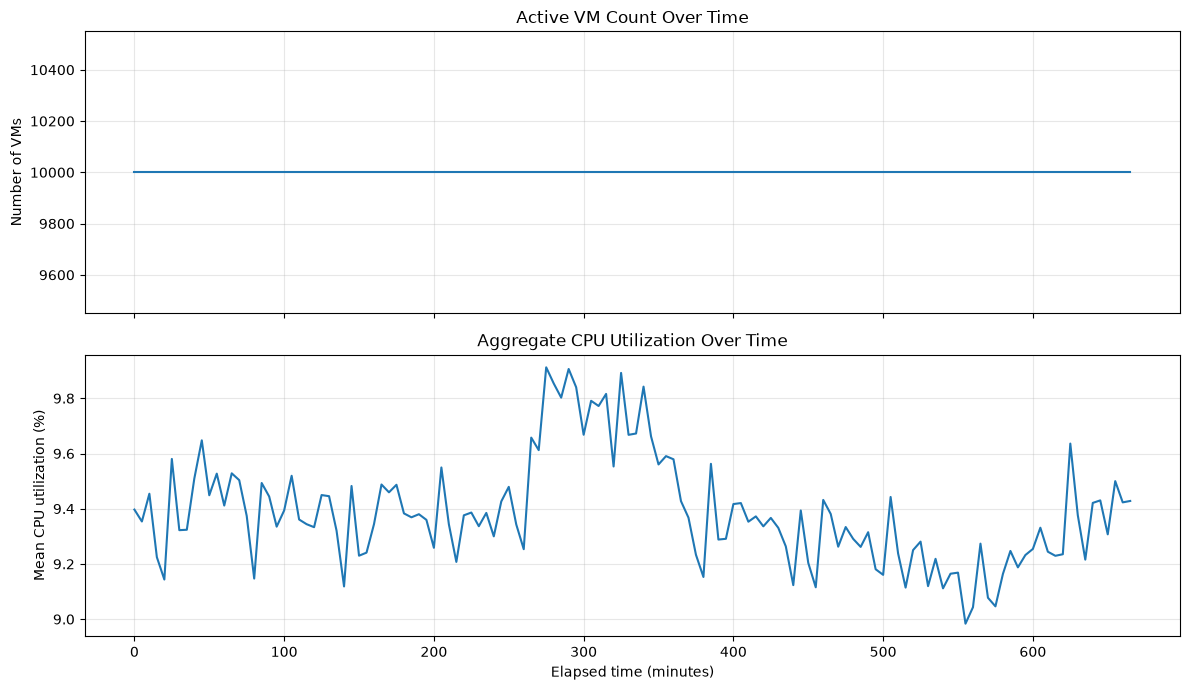

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(
    aggregate["elapsed_minutes"],
    aggregate["active_vm_count"],
)
axes[0].set_title("Active VM Count Over Time")
axes[0].set_ylabel("Number of VMs")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    aggregate["elapsed_minutes"],
    aggregate["aggregate_cpu_utilization"],
)
axes[1].set_title("Aggregate CPU Utilization Over Time")
axes[1].set_xlabel("Elapsed time (minutes)")
axes[1].set_ylabel("Mean CPU utilization (%)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_12632\2962660642.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


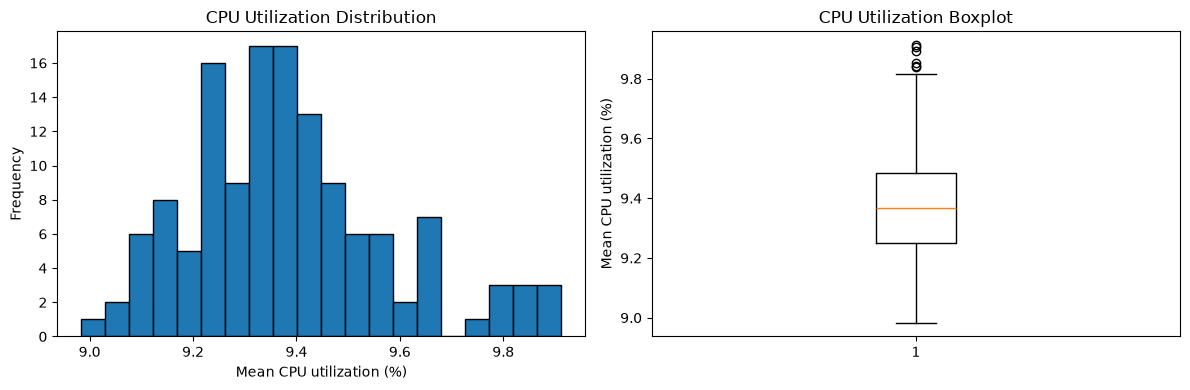

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    aggregate["aggregate_cpu_utilization"],
    bins=20,
    edgecolor="black",
)
axes[0].set_title("CPU Utilization Distribution")
axes[0].set_xlabel("Mean CPU utilization (%)")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(
    aggregate["aggregate_cpu_utilization"],
    vert=True,
)
axes[1].set_title("CPU Utilization Boxplot")
axes[1].set_ylabel("Mean CPU utilization (%)")

plt.tight_layout()
plt.show()

count    133.000000
mean       0.000235
std        0.156254
min       -0.274332
25%       -0.106904
50%       -0.016914
75%        0.078342
max        0.436831
Name: cpu_change, dtype: float64


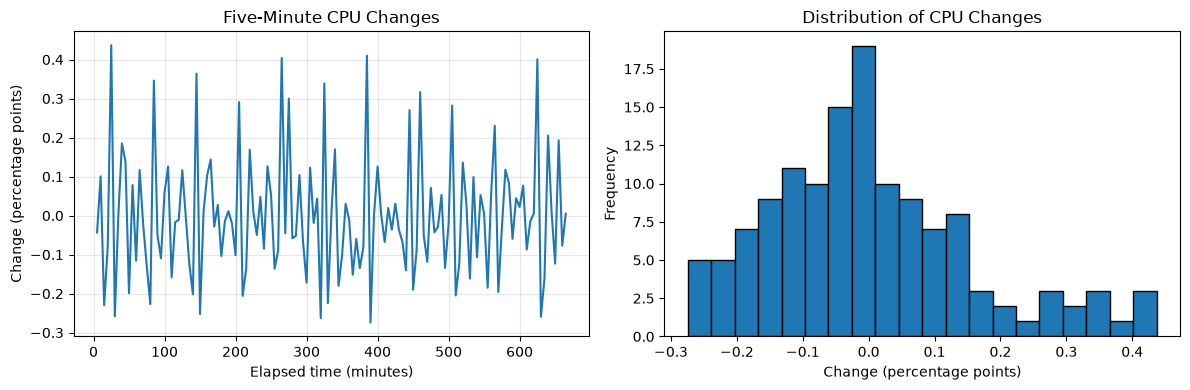

In [7]:
aggregate["cpu_change"] = (aggregate["aggregate_cpu_utilization"].diff())
print(aggregate["cpu_change"].describe())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(aggregate["elapsed_minutes"],aggregate["cpu_change"],)
axes[0].set_title("Five-Minute CPU Changes")
axes[0].set_xlabel("Elapsed time (minutes)")
axes[0].set_ylabel("Change (percentage points)")
axes[0].grid(True, alpha=0.3)

axes[1].hist(aggregate["cpu_change"].dropna(),bins=20,edgecolor="black",)
axes[1].set_title("Distribution of CPU Changes")
axes[1].set_xlabel("Change (percentage points)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

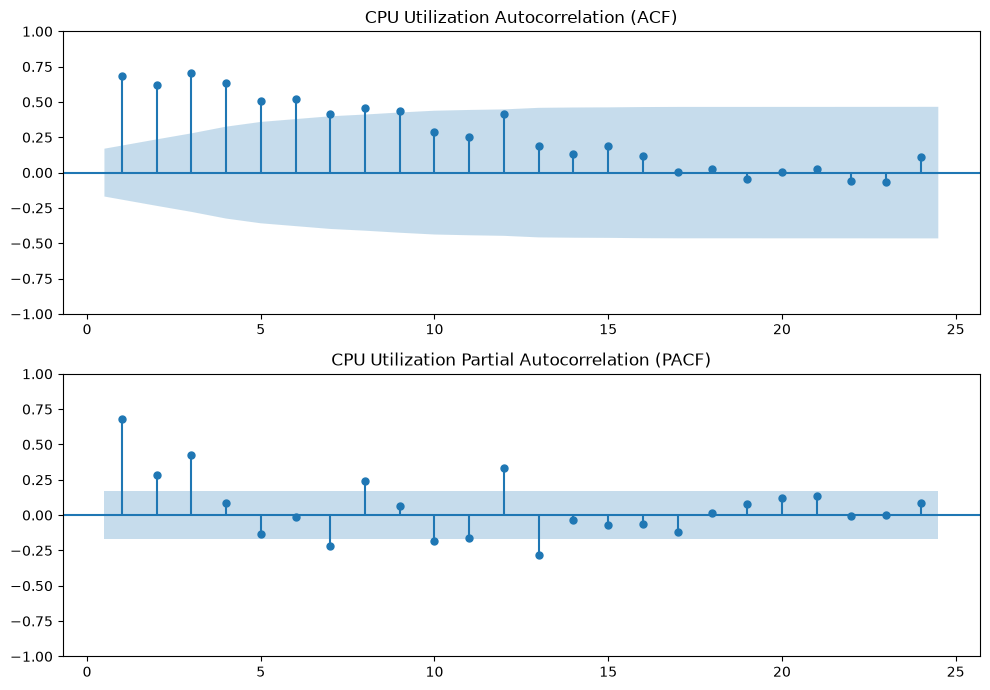

In [8]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src" / "data.py").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate src/data.py")
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data import load_data

cpu_readings, vm_metadata = load_data(PROJECT_ROOT / "data" / "raw")

aggregate = (
    cpu_readings.groupby("timestamp")
    .agg(
        active_vm_count=("vm_id", "nunique"),
        aggregate_cpu_utilization=("avg_cpu", "mean"),
    )
    .sort_values("timestamp")
    .reset_index()
)

cpu = aggregate["aggregate_cpu_utilization"]

fig, axes = plt.subplots(2, 1, figsize=(10, 7))

plot_acf(cpu, lags=24, ax=axes[0], zero=False)
axes[0].set_title("CPU Utilization Autocorrelation (ACF)")

plot_pacf(cpu, lags=24, method="ywm", ax=axes[1], zero=False)
axes[1].set_title("CPU Utilization Partial Autocorrelation (PACF)")

plt.tight_layout()
plt.show()

In [9]:
from statsmodels.tsa.stattools import adfuller, kpss

adf_result = adfuller(cpu, autolag="AIC")
kpss_result = kpss(cpu, regression="c", nlags="auto")

print("ADF test")
print("Statistic:", adf_result[0])
print("P-value:", adf_result[1])
print("Used lags:", adf_result[2])

print("\nKPSS test")
print("Statistic:", kpss_result[0])
print("P-value:", kpss_result[1])
print("Used lags:", kpss_result[2])

ADF test
Statistic: -2.1689624560908833
P-value: 0.2177024775883506
Used lags: 12

KPSS test
Statistic: 0.44541509014721875
P-value: 0.05757970252275055
Used lags: 6


C:\Users\User\AppData\Local\Temp\ipykernel_12632\2584462665.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(cpu, autolag="AIC")
C:\Users\User\AppData\Local\Temp\ipykernel_12632\2584462665.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(cpu, regression="c", nlags="auto")


In [10]:
from scipy.stats import linregress
import numpy as np

trend = linregress(
    np.arange(len(cpu)),
    cpu,
)

print("Estimated change per five minutes:", trend.slope)
print("Estimated change per hour:", trend.slope * 12)
print("R-squared:", trend.rvalue ** 2)
print("P-value:", trend.pvalue)

Estimated change per five minutes: -0.0014422024999742897
Estimated change per hour: -0.017306429999691477
R-squared: 0.08247058903993795
P-value: 0.000767312344285996


In [11]:
development_cpu = cpu.iloc[:110]
peak_threshold = development_cpu.quantile(0.90)

print("Development 90th-percentile threshold:", peak_threshold)

print("\nHighest CPU observations in development:")
print(
    aggregate.iloc[:110][
        ["timestamp", "aggregate_cpu_utilization"]
    ].nlargest(10, "aggregate_cpu_utilization")
)

Development 90th-percentile threshold: 9.668361517488389

Highest CPU observations in development:
    timestamp  aggregate_cpu_utilization
55      16500                   9.912175
58      17400                   9.906192
65      19500                   9.891946
56      16800                   9.853998
68      20400                   9.842210
59      17700                   9.839981
63      18900                   9.815904
57      17100                   9.802439
61      18300                   9.790885
62      18600                   9.772086


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

folds = [
    (62, 86),
    (74, 98),
    (86, 110),
]

def forecast_persistence(history, horizon):
    return np.repeat(history[-1], horizon)

def forecast_moving_average(history, horizon, window=6):
    return np.repeat(history[-window:].mean(), horizon)

baseline_results = []

for fold_number, (train_end, val_end) in enumerate(folds, start=1):
    history = cpu.iloc[:train_end].to_numpy()
    actual = cpu.iloc[train_end:val_end].to_numpy()

    for name, forecast_fn in [
        ("Persistence", forecast_persistence),
        ("Moving average (6 points)", forecast_moving_average),
    ]:
        predictions = forecast_fn(history, len(actual))

        baseline_results.append({
            "fold": fold_number,
            "model": name,
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        })

baseline_results = pd.DataFrame(baseline_results)

print(baseline_results)

print("\nMean metrics across folds:")
print(
    baseline_results.groupby("model")[["MAE", "RMSE"]]
    .mean()
    .sort_values("MAE")
)

   fold                      model       MAE      RMSE
0     1                Persistence  0.297486  0.345731
1     1  Moving average (6 points)  0.311997  0.361724
2     2                Persistence  0.124450  0.152192
3     2  Moving average (6 points)  0.295606  0.312754
4     3                Persistence  0.132429  0.154228
5     3  Moving average (6 points)  0.139638  0.162600

Mean metrics across folds:
                                MAE      RMSE
model                                        
Persistence                0.184788  0.217384
Moving average (6 points)  0.249080  0.279026


## VM Lifetimes and Workload Segments

The metadata timestamps are compared with the observed trace window to check whether VM starts or exits occur during these 134 readings. Segment summaries are calculated from each VM's CPU readings, then grouped by workload category and virtual-core bucket. The p95 column is the median of per-VM 95th-percentile `avg_cpu` values; groups are descriptive and do not imply causal differences.

In [ ]:
trace_start = int(cpu_readings["timestamp"].min())
trace_end = int(cpu_readings["timestamp"].max())

vm_lifetimes = vm_metadata.assign(
    lifetime_seconds=(
        vm_metadata["timestamp_vm_deleted"]
        - vm_metadata["timestamp_vm_created"]
    ),
    covers_trace=(
        (vm_metadata["timestamp_vm_created"] <= trace_start)
        & (vm_metadata["timestamp_vm_deleted"] > trace_end)
    ),
)

print(f"Observed trace: {trace_start:,} to {trace_end:,} seconds")
print(
    "VMs whose recorded lifetime covers the complete trace:",
    f"{int(vm_lifetimes['covers_trace'].sum()):,} / {len(vm_lifetimes):,}",
)
print(
    "VMs created after the trace began:",
    int((vm_lifetimes["timestamp_vm_created"] > trace_start).sum()),
)
print(
    "VMs deleted by the final trace timestamp:",
    int((vm_lifetimes["timestamp_vm_deleted"] <= trace_end).sum()),
)
display(
    vm_lifetimes["lifetime_seconds"]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
    .to_frame("lifetime_seconds")
)

per_vm_workload = (
    cpu_readings.groupby("vm_id")
    .agg(
        mean_avg_cpu=("avg_cpu", "mean"),
        p95_avg_cpu=("avg_cpu", lambda values: values.quantile(0.95)),
    )
    .reset_index()
    .merge(
        vm_metadata[["vm_id", "vm_category", "virtual_core_bucket"]],
        on="vm_id",
        validate="one_to_one",
    )
)

def summarize_vm_segments(segment_column):
    return (
        per_vm_workload.groupby(segment_column, observed=True)
        .agg(
            vm_count=("vm_id", "nunique"),
            mean_of_vm_means=("mean_avg_cpu", "mean"),
            median_vm_mean=("mean_avg_cpu", "median"),
            median_vm_p95=("p95_avg_cpu", "median"),
            p90_vm_p95=("p95_avg_cpu", lambda values: values.quantile(0.90)),
        )
        .round(3)
        .sort_values("vm_count", ascending=False)
    )

print("Per-VM workload summary by category")
display(summarize_vm_segments("vm_category"))
print("Per-VM workload summary by virtual-core bucket")
display(summarize_vm_segments("virtual_core_bucket"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
per_vm_workload.boxplot(
    column="mean_avg_cpu",
    by="vm_category",
    ax=axes[0],
    grid=False,
    showfliers=False,
)
axes[0].set_title("Per-VM Mean CPU by Category")
axes[0].set_xlabel("VM category")
axes[0].set_ylabel("Per-VM mean avg_cpu (%)")
axes[0].tick_params(axis="x", rotation=20)

core_order = ["2", "4", "8", "24", ">24"]
per_vm_workload["virtual_core_bucket"] = pd.Categorical(
    per_vm_workload["virtual_core_bucket"],
    categories=core_order,
    ordered=True,
)
per_vm_workload.boxplot(
    column="mean_avg_cpu",
    by="virtual_core_bucket",
    ax=axes[1],
    grid=False,
    showfliers=False,
)
axes[1].set_title("Per-VM Mean CPU by vCPU Bucket")
axes[1].set_xlabel("Virtual-core bucket")
axes[1].set_ylabel("Per-VM mean avg_cpu (%)")
plt.suptitle("Workload Differences Across VM Segments")
plt.tight_layout()
plt.show()